# Docile loader class

In [1]:
%pip install httpx

In [74]:
from dataclasses import dataclass, field
from enum import StrEnum
from pathlib import Path
from urllib.parse import quote
from zipfile import ZipFile, is_zipfile
from getpass import getpass

import httpx
from tqdm.std import tqdm
import pandas as pd
import json
from dataclasses import asdict
from typing import Literal

import pandas as pd
from tqdm.std import tqdm

In [76]:
UNLABELED_CHUNK_MAX = 93

BASELINE_VARIANTS = (
    "roberta-base",
    "roberta-ours",
    "layoutlmv3-ours",
    "roberta-pretraining",
    "layoutlmv3-pretraining",
    "detr",
    "roberta-base-with-synthetic-pretraining",
    "roberta-ours-with-synthetic-pretraining",
    "layoutlmv3-ours-with-synthetic-pretraining",
)


DocileDataset = StrEnum(
    "DocileDataset",
    {
        "ANNOTATED_TRAINVAL": "annotated-trainval",
        "SYNTHETIC": "synthetic",
        "UNLABELED": "unlabeled",
        "UNLABELED_ANNOTATIONS": "unlabeled-annotations",
        "BASELINES": "baselines",
        "BASELINES_20230315": "baselines-20230315",

        # synthetic-chunk-0 through synthetic-chunk-9
        **{
            f"SYNTHETIC_CHUNK_{index}": f"synthetic-chunk-{index}"
            for index in range(10)
        },

        # unlabeled-chunk-00 through unlabeled-chunk-93
        **{
            f"UNLABELED_CHUNK_{index:02d}": f"unlabeled-chunk-{index:02d}"
            for index in range(UNLABELED_CHUNK_MAX + 1)
        },

        # unlabeled-chunk-ocr-only-00 through ...-93
        **{
            f"UNLABELED_CHUNK_OCR_ONLY_{index:02d}": (
                f"unlabeled-chunk-ocr-only-{index:02d}"
            )
            for index in range(UNLABELED_CHUNK_MAX + 1)
        },

        # Individual archives from either baseline selection.
        **{
            f"{base}-{variant}".replace("-", "_").upper(): (
                f"{base}-{variant}"
            )
            for base in ("baselines", "baselines-20230315")
            for variant in BASELINE_VARIANTS
        },
    },
)

@dataclass
class DocileDatasetDownloader:
    token: str = field(repr=False)
    dataset: DocileDataset = DocileDataset.ANNOTATED_TRAINVAL
    target_dir: str | Path = "data/docile"
    unzip: bool = False
    without_pdfs: bool = False
    minimum_archive_bytes: int = 100_000_000

    def __post_init__(self):
        # Also validates callers passing a plain string.
        self.dataset = DocileDataset(self.dataset)
        self.target_dir = Path(self.target_dir).expanduser()

        if not self.token.strip():
            raise ValueError("A download token is required.")

        if self.minimum_archive_bytes < 0:
            raise ValueError("minimum_archive_bytes cannot be negative.")

        if (
            self.without_pdfs
            and self.dataset != DocileDataset.UNLABELED
        ):
            raise ValueError(
                "without_pdfs is supported only for dataset='unlabeled'."
            )

    def archive_names(self) -> list[str]:
        """Expand the selected dataset into downloadable archive names."""
        if self.dataset == DocileDataset.UNLABELED:
            prefix = (
                "unlabeled-chunk-ocr-only"
                if self.without_pdfs
                else "unlabeled-chunk"
            )

            return ["unlabeled-annotations"] + [
                f"{prefix}-{index:02d}"
                for index in range(UNLABELED_CHUNK_MAX + 1)
            ]

        if self.dataset in {
            DocileDataset.BASELINES,
            DocileDataset.BASELINES_20230315,
        }:
            return [
                f"{self.dataset.value}-{variant}"
                for variant in BASELINE_VARIANTS
            ]

        return [self.dataset.value]

    def download_urls(self) -> list[str]:
        """Return URLs containing the token, equivalent to --show-urls."""
        base_url = (
            "https://docile-dataset-rossum.s3.eu-west-1.amazonaws.com"
        )
        token = quote(self.token, safe="")

        return [
            f"{base_url}/{token}/{name}.zip"
            for name in self.archive_names()
        ]

    def _validate_archive(self, path: Path) -> None:
        if path.stat().st_size < self.minimum_archive_bytes:
            raise ValueError(
                f"{path.name} is smaller than the expected minimum size."
            )

        if not is_zipfile(path):
            raise ValueError(f"{path.name} is not a valid ZIP archive.")

    def _download_archive(
        self,
        client: httpx.Client,
        name: str,
        url: str,
    ) -> Path:
        archive_path = self.target_dir / f"{name}.zip"

        if archive_path.is_file():
            self._validate_archive(archive_path)
            return archive_path

        temporary_path = archive_path.with_suffix(".zip.part")

        try:
            with client.stream("GET", url) as response:
                response.raise_for_status()

                content_length = response.headers.get("Content-Length")
                total_bytes = (
                    int(content_length)
                    if content_length
                    else None
                )

                with (
                    temporary_path.open("wb") as output,
                    tqdm(
                        total=total_bytes,
                        desc=name,
                        unit="B",
                        unit_scale=True,
                        unit_divisor=1024,
                    ) as progress,
                ):
                    for chunk in response.iter_bytes(
                        chunk_size=1024 * 1024
                    ):
                        output.write(chunk)
                        progress.update(len(chunk))

            self._validate_archive(temporary_path)
            temporary_path.replace(archive_path)

        except httpx.HTTPStatusError as exc:
            status = exc.response.status_code
            request_id = exc.response.headers.get("x-amz-request-id", "unknown")

            raise RuntimeError(
                f"Download failed for {name}.zip: HTTP {status}. "
                f"S3 request ID: {request_id}"
            ) from None

        except httpx.TimeoutException as exc:
            raise RuntimeError(
                f"Download timed out for {name}.zip "
                f"({type(exc).__name__})."
            ) from None

        except httpx.RequestError as exc:
            raise RuntimeError(
                f"Connection failed for {name}.zip "
                f"({type(exc).__name__})."
            ) from None

        finally:
            temporary_path.unlink(missing_ok=True)

        return archive_path

    def download(self) -> Path:
        """Download archives; optionally extract and delete each ZIP."""
        self.target_dir.mkdir(parents=True, exist_ok=True)

        with httpx.Client(
            follow_redirects=True,
            timeout=httpx.Timeout(120.0, connect=30.0),
        ) as client:
            for name, url in zip(
                self.archive_names(),
                self.download_urls(),
            ):
                archive_path = self._download_archive(client, name, url)

                if self.unzip:
                    with ZipFile(archive_path) as archive:
                        archive.extractall(self.target_dir)

                    archive_path.unlink()

        return self.target_dir

In [2]:
token = getpass("DoCile token: ")

In [12]:
downloader = DocileDatasetDownloader(
    token=token,
    dataset=DocileDataset.ANNOTATED_TRAINVAL,
    target_dir="/content/docile",
    unzip=True,
)

dataset_path = downloader.download()
dataset_path

annotated-trainval: 100%|██████████| 1.06G/1.06G [01:01<00:00, 18.6MB/s]


PosixPath('/content/docile')

In [13]:
!ls -la /content/docile

total 1276
drwxr-xr-x 5 root root   4096 Nov  2 19:13 .
drwxr-xr-x 1 root root   4096 Nov  2 19:08 ..
drwxr-xr-x 2 root root 327680 Nov  2 19:13 annotations
drwxr-xr-x 2 root root 327680 Nov  2 19:13 ocr
drwxr-xr-x 2 root root 286720 Nov  2 19:13 pdfs
-rw-r--r-- 1 root root 155402 Nov  2 19:13 train.json
-rw-r--r-- 1 root root 170402 Nov  2 19:13 trainval.json
-rw-r--r-- 1 root root  15002 Nov  2 19:13 val.json


In [16]:
!cat /content/docile/trainval.json

[
  "00134dd365a24343b35b78c6",
  "00136a27c7774c1e8dc6b2f2",
  "002e3cf97973428f905671b3",
  "002f9b82b74f4258b3b072d0",
  "003568b1286f4dab953fc2d5",
  "0039ed9f32974a90afb4f8f2",
  "003cc91637994b7d9566ac41",
  "00405d767fb1406180d05ef2",
  "004e76fe452448eebaadc53b",
  "006835846482455e8d75f8f8",
  "0079863fa739477290959e5d",
  "0087b1c5608a443995fe9656",
  "008ca3c5e4024ce2aa2c77e2",
  "0091f649d0c746f8abec5e16",
  "0096d69f865b443290705bee",
  "009bdcdec5c04cd3b2e31555",
  "00a5c8697856473393f3f9e2",
  "00aa98164d264f4e924f55a9",
  "00bc2d75785b4c02a3454a48",
  "00c26149c99647a088299e3b",
  "00c87916e4a44197b45b0f8b",
  "00ccfe1a0a96487cb67f3925",
  "00e7f330e0344e9abdef3073",
  "00e9a4cf34a046199a0b3bb4",
  "00ecc5c210c54030a0c76eff",
  "00f290a2e79045878780ad0a",
  "0100fa8313bf4d3489c55c81",
  "011510a48eb3468192a4aa44",
  "01188ef591384224a527a94a",
  "01306f143c9142899afc2e6c",
  "0133788ff6914aa09df4d064",
  "013feac0924a49e396b966d7",
  "015f35badb50413fab2ea1be",
  "01628

In [17]:
!ls -la /content/docile/annotations

total 95852
drwxr-xr-x 2 root root 327680 Nov  2 19:13 .
drwxr-xr-x 5 root root   4096 Nov  2 19:13 ..
-rw-r--r-- 1 root root   9777 Nov  2 19:13 00134dd365a24343b35b78c6.json
-rw-r--r-- 1 root root  51099 Nov  2 19:13 00136a27c7774c1e8dc6b2f2.json
-rw-r--r-- 1 root root   9428 Nov  2 19:13 002e3cf97973428f905671b3.json
-rw-r--r-- 1 root root  11993 Nov  2 19:13 002f9b82b74f4258b3b072d0.json
-rw-r--r-- 1 root root  17447 Nov  2 19:13 003568b1286f4dab953fc2d5.json
-rw-r--r-- 1 root root   7047 Nov  2 19:13 0039ed9f32974a90afb4f8f2.json
-rw-r--r-- 1 root root  13657 Nov  2 19:13 003cc91637994b7d9566ac41.json
-rw-r--r-- 1 root root   5355 Nov  2 19:13 00405d767fb1406180d05ef2.json
-rw-r--r-- 1 root root   8253 Nov  2 19:13 004e76fe452448eebaadc53b.json
-rw-r--r-- 1 root root  45111 Nov  2 19:13 006835846482455e8d75f8f8.json
-rw-r--r-- 1 root root  25240 Nov  2 19:13 0079863fa739477290959e5d.json
-rw-r--r-- 1 root root  10399 Nov  2 19:13 0087b1c5608a443995fe9656.json
-rw-r--r-- 1 root roo

In [18]:
!cat /content/docile/annotations/00134dd365a24343b35b78c6.json

{
  "field_extractions": [
    {
      "bbox": [
        0.7825308989140187,
        0.34950390316404,
        0.8833072215750077,
        0.36071127298046407
      ],
      "fieldtype": "document_id",
      "page": 0,
      "text": "990304502"
    },
    {
      "bbox": [
        0.7830815892017836,
        0.36320179960633614,
        0.8717427255319434,
        0.3752393449647175
      ],
      "fieldtype": "date_issue",
      "page": 0,
      "text": "03/25/99"
    },
    {
      "bbox": [
        0.2279857791346965,
        0.4208989997723712,
        0.2836054981989582,
        0.43335163290173134
      ],
      "fieldtype": "customer_order_id",
      "page": 0,
      "text": "29350"
    },
    {
      "bbox": [
        0.0726911179849757,
        0.1801480926047427,
        0.46368122229810255,
        0.2038080955505269
      ],
      "fieldtype": "vendor_name",
      "page": 0,
      "text": "BIO RELIANCE Testing & Development, Inc."
    },
    {
      "bbox": [
        0.0738

In [19]:
!ls -la /content/docile/ocr

total 445596
drwxr-xr-x 2 root root 327680 Nov  2 19:13 .
drwxr-xr-x 5 root root   4096 Nov  2 19:13 ..
-rw-r--r-- 1 root root  49205 Nov  2 19:13 00134dd365a24343b35b78c6.json
-rw-r--r-- 1 root root 116466 Nov  2 19:13 00136a27c7774c1e8dc6b2f2.json
-rw-r--r-- 1 root root  36875 Nov  2 19:13 002e3cf97973428f905671b3.json
-rw-r--r-- 1 root root 121065 Nov  2 19:13 002f9b82b74f4258b3b072d0.json
-rw-r--r-- 1 root root  81047 Nov  2 19:13 003568b1286f4dab953fc2d5.json
-rw-r--r-- 1 root root  43165 Nov  2 19:13 0039ed9f32974a90afb4f8f2.json
-rw-r--r-- 1 root root  46204 Nov  2 19:13 003cc91637994b7d9566ac41.json
-rw-r--r-- 1 root root  22289 Nov  2 19:13 00405d767fb1406180d05ef2.json
-rw-r--r-- 1 root root 123363 Nov  2 19:13 004e76fe452448eebaadc53b.json
-rw-r--r-- 1 root root 220948 Nov  2 19:13 006835846482455e8d75f8f8.json
-rw-r--r-- 1 root root 104003 Nov  2 19:13 0079863fa739477290959e5d.json
-rw-r--r-- 1 root root  28727 Nov  2 19:13 0087b1c5608a443995fe9656.json
-rw-r--r-- 1 root ro

In [20]:
!cat /content/docile/ocr/00134dd365a24343b35b78c6.json

{"pages": [{"page_idx": 0, "dimensions": [1616, 1218], "orientation": {"value": null, "confidence": null}, "language": {"value": null, "confidence": null}, "blocks": [{"geometry": [[0.5224609375, 0.16796875], [0.66015625, 0.224609375]], "lines": [{"geometry": [[0.5224609375, 0.16796875], [0.66015625, 0.181640625]], "words": [{"value": "WIRE", "confidence": 0.9773061871528625, "geometry": [[0.5224609375, 0.1689453125], [0.5595703125, 0.1806640625]], "snapped_geometry": [[0.5254137115839244, 0.17015590200445435], [0.5567375886524822, 0.17817371937639198]]}, {"value": "INSTRUCTIONS:", "confidence": 0.7344109416007996, "geometry": [[0.5595703125, 0.16796875], [0.66015625, 0.181640625]], "snapped_geometry": [[0.5644208037825059, 0.1706013363028953], [0.6572104018912529, 0.17861915367483297]]}]}, {"geometry": [[0.5234375, 0.1796875], [0.626953125, 0.1923828125]], "words": [{"value": "NationsBank,", "confidence": 0.8877716660499573, "geometry": [[0.5234375, 0.1796875], [0.599609375, 0.1923828

In [21]:
import json

from collections.abc import Iterator
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any


BBox = tuple[float, float, float, float]


@dataclass(frozen=True)
class OCRWord:
    text: str
    bbox: BBox
    page: int
    start: int
    end: int
    confidence: float | None
    block_index: int
    line_index: int
    word_index: int


@dataclass
class DocileRecord:
    document_id: str
    ocr_text: str
    text_with_boxes: list[OCRWord]
    json_data: dict[str, Any]

In [59]:
from dataclasses import dataclass
from typing import Any, ClassVar


@dataclass
class DocileAnnotationConverter:
    FIELD_MAPPING: ClassVar[dict[str, tuple[str, str]]] = {
        "document_id": ("invoice", "invoice_number"),
        "date_issue": ("invoice", "invoice_date"),
        "date_due": ("invoice", "due_date"),
        "vendor_name": ("invoice", "seller_name"),
        "vendor_address": ("invoice", "seller_address"),
        "customer_billing_name": ("invoice", "client_name"),
        "customer_billing_address": ("invoice", "client_address"),
        "account_num": ("payment_instructions", "account_number"),
        "payment_terms": ("payment_instructions", "payment_terms"),
        "amount_total_gross": ("subtotal", "total"),
        "amount_total_tax": ("subtotal", "tax"),
    }

    ITEM_MAPPING: ClassVar[dict[str, str]] = {
        "line_item_description": "description",
        "line_item_quantity": "quantity",
        "line_item_units_of_measure": "units_of_measure",
        "line_item_code": "code",
        "line_item_unit_price_gross": "unit_price",
        "line_item_amount_gross": "total_price",
    }

    @staticmethod
    def _add_field(
        destination: dict,
        name: str,
        field: dict,
        *,
        join_fragments: bool = False,
    ) -> None:
        entry = destination.setdefault(
            name,
            {
                "value": field["text"],
                "bbox": [],
                "pages": [],
                "source_values": [],
            },
        )

        entry["bbox"].append(list(field["bbox"]))
        entry["pages"].append(field["page"])
        entry["source_values"].append(field["text"])

        if join_fragments:
            entry["value"] = "\n".join(
                dict.fromkeys(entry["source_values"])
            )

    def convert(self, annotation: dict[str, Any]) -> dict[str, Any]:
        """Convert annotations without discarding unmapped fields or locations."""
        result = {
            "invoice": {},
            "payment_instructions": {},
            "subtotal": {},
            "other_fields": {},
            "items": [],
            "line_item_headers": {},
            "metadata": annotation.get("metadata", {}),
        }

        for field in annotation.get("field_extractions", []):
            fieldtype = field["fieldtype"]

            section, name = self.FIELD_MAPPING.get(
                fieldtype,
                ("other_fields", fieldtype),
            )

            self._add_field(result[section], name, field)

        items_by_id = {}

        for field in annotation.get("line_item_extractions", []):
            item_id = field["line_item_id"]

            item = items_by_id.setdefault(
                item_id,
                {
                    "line_item_id": item_id,
                    "fields": {},
                },
            )

            fieldtype = field["fieldtype"]
            name = self.ITEM_MAPPING.get(
                fieldtype,
                fieldtype.removeprefix("line_item_"),
            )

            self._add_field(
                item["fields"],
                name,
                field,
                join_fragments=name == "description",
            )

        result["items"] = list(items_by_id.values())

        for field in annotation.get("line_item_headers", []):
            fieldtype = field["fieldtype"]
            name = self.ITEM_MAPPING.get(
                fieldtype,
                fieldtype.removeprefix("line_item_"),
            )

            self._add_field(
                result["line_item_headers"],
                name,
                field,
            )

        return result

In [82]:
from dataclasses import dataclass, replace
from statistics import median


@dataclass
class OCRReadingOrder:
    # Maximum vertical distance from the row center,
    # expressed as a fraction of the median word height.
    row_tolerance: float = 0.5

    def build(
        self,
        words: list["OCRWord"],
    ) -> tuple[str, list["OCRWord"]]:
        """Order words by page and visual row, then rebuild text offsets.

        This uses horizontal reading order. It does not detect columns
        or reconstruct table structure.
        """
        if not words:
            return "", []

        pages = {}

        for word in words:
            if word.text:
                pages.setdefault(word.page, []).append(word)

        ordered_words = []

        for page_index in sorted(pages):
            page_words = pages[page_index]

            heights = [
                word.bbox[3] - word.bbox[1]
                for word in page_words
                if word.bbox[3] > word.bbox[1]
            ]

            if not heights:
                raise ValueError(
                    f"Page {page_index} has no valid word heights"
                )

            tolerance = median(heights) * self.row_tolerance

            # Each row stores its words and vertical center positions.
            rows = []

            for word in sorted(
                page_words,
                key=lambda word: (
                    self._center_y(word),
                    word.bbox[0],
                ),
            ):
                center_y = self._center_y(word)

                if rows:
                    row = rows[-1]
                    row_center = median(row["centers"])
                else:
                    row = None

                if row is None or center_y - row_center > tolerance:
                    row = {"words": [], "centers": []}
                    rows.append(row)

                row["words"].append(word)
                row["centers"].append(center_y)

            for row in rows:
                ordered_words.extend(
                    sorted(
                        row["words"],
                        key=lambda word: word.bbox[0],
                    )
                )

        parts = []
        rebuilt_words = []
        position = 0

        for word in ordered_words:
            if parts:
                parts.append(" ")
                position += 1

            start = position
            parts.append(word.text)
            position += len(word.text)

            rebuilt_words.append(
                replace(
                    word,
                    start=start,
                    end=position,
                )
            )

        return "".join(parts), rebuilt_words

    @staticmethod
    def _center_y(word: "OCRWord") -> float:
        return (word.bbox[1] + word.bbox[3]) / 2


In [83]:
@dataclass
class DocileDatasetLoader:
    root: str | Path
    use_snapped_boxes: bool = True

    def __post_init__(self):
        self.root = Path(self.root).expanduser()

    @staticmethod
    def _parse_box(geometry: list) -> BBox:
        """Convert OCR corners to the annotation box format."""
        if len(geometry) != 2:
            raise ValueError(f"Expected two box corners: {geometry!r}")

        (left, top), (right, bottom) = geometry

        return (
            float(left),
            float(top),
            float(right),
            float(bottom),
        )

    def document_ids(self, split: str = "train") -> list[str]:
        if split not in {"train", "val", "trainval"}:
            raise ValueError("split must be 'train', 'val' or 'trainval'.")

        path = self.root / f"{split}.json"

        with path.open(encoding="utf-8") as file:
            document_ids = json.load(file)

        if not isinstance(document_ids, list) or not all(
            isinstance(document_id, str)
            for document_id in document_ids
        ):
            raise ValueError(f"{path} must contain a list of document IDs.")

        return document_ids

    def load(self, document_id: str) -> DocileRecord:
        """Load OCR and annotations while preserving OCR text and offsets.

        Text follows the stored page/block/line/word order. Words are joined
        by spaces, lines by newlines, and pages by a form-feed separator.
        Annotation JSON is preserved without flattening or merging fields.
        """
        if (
            not document_id
            or document_id in {".", ".."}
            or "/" in document_id
            or "\\" in document_id
        ):
            raise ValueError("document_id must be a file stem.")

        annotation_path = (
            self.root / "annotations" / f"{document_id}.json"
        )
        ocr_path = self.root / "ocr" / f"{document_id}.json"

        with annotation_path.open(encoding="utf-8") as file:
            json_data = json.load(file)

        with ocr_path.open(encoding="utf-8") as file:
            ocr_data = json.load(file)

        parts = []
        words = []
        position = 0
        previous_page = None

        for page_position, page in enumerate(ocr_data["pages"]):
            page_index = int(page.get("page_idx", page_position))

            for block_index, block in enumerate(page["blocks"]):
                for line_index, line in enumerate(block["lines"]):
                    line_words = [
                        (word_index, word)
                        for word_index, word in enumerate(line["words"])
                        if word["value"].strip()
                    ]

                    if not line_words:
                        continue

                    if parts:
                        # separator = (
                        #     "\n"
                        #     if previous_page == page_index
                        #     else "\n\f\n"
                        # )
                        separator = " "
                        parts.append(separator)
                        position += len(separator)

                    for index_in_line, (word_index, word) in enumerate(
                        line_words
                    ):
                        if index_in_line:
                            parts.append(" ")
                            position += 1

                        value = word["value"]

                        geometry = word["geometry"]
                        if self.use_snapped_boxes:
                            geometry = (
                                word.get("snapped_geometry") or geometry
                            )

                        start = position
                        parts.append(value)
                        position += len(value)

                        words.append(
                            OCRWord(
                                text=value,
                                bbox=self._parse_box(geometry),
                                page=page_index,
                                start=start,
                                end=position,
                                confidence=word.get("confidence"),
                                block_index=block_index,
                                line_index=line_index,
                                word_index=word_index,
                            )
                        )

                    previous_page = page_index

        ocr_text = "".join(parts)

        ocr_text, words = OCRReadingOrder().build(words)
        json_data = DocileAnnotationConverter().convert(json_data)
        
        return DocileRecord(
            document_id=document_id,
            ocr_text=ocr_text,
            text_with_boxes=words,
            json_data=json_data,
        )

    def iter_split(
        self,
        split: str = "train",
    ) -> Iterator[DocileRecord]:
        """Load documents one at a time rather than preloading the split."""
        for document_id in self.document_ids(split):
            yield self.load(document_id)

    def document_ids(
        self,
        split: Literal["train", "val", "trainval"] = "trainval",
    ) -> list[str]:
        split_path = self.root / f"{split}.json"

        with split_path.open(encoding="utf-8") as file:
            return json.load(file)


    def to_dataframe(
        self,
        split: Literal["train", "val", "trainval"] = "trainval",
        *,
        show_progress: bool = True,
    ) -> pd.DataFrame:
        """Load a split, preserving nested annotations and OCR word metadata."""
        document_ids = self.document_ids(split)
        rows = []

        for document_id in tqdm(
            document_ids,
            desc=f"Loading {split}",
            unit="document",
            disable=not show_progress,
        ):
            try:
                record = self.load(document_id)
            except Exception as exc:
                raise RuntimeError(
                    f"Failed to load document {document_id}"
                ) from exc

            rows.append(
                {
                    "document_id": record.document_id,
                    "ocr_text": record.ocr_text,
                    "text_with_boxes": [
                        asdict(word)
                        for word in record.text_with_boxes
                    ],
                    "json_data": record.json_data,
                    "pdf_path": str(
                        self.root / "pdfs" / f"{document_id}.pdf"
                    ),
                }
            )

        return pd.DataFrame(
            rows
        )

In [61]:
loader = DocileDatasetLoader("/content/docile")

In [62]:
record = loader.load("00134dd365a24343b35b78c6")

In [63]:
record.ocr_text

'WIRE INSTRUCTIONS: NationsBank, N.A. Baltimore, MD 21202 Routing No. 052001633 REMIT TO: BioReliance Testing & Development, Inc. MA BioServices, Inc. is acceptable) NationsBank, N.A. PO. Box 630312 Baltimore, MD. 21263-0312 39 163 63663 BIORELIANCE 14920 Broschart Road . Rockville, MD. 20850-3349 USA Phone 301.738.1000 . Fax 301.251.0437 Formerly Microbiological. Associates, Inc. MAI BjoServices, Inc. Testing & Development, Inc. 100 South Charles Street (former payee designate FOR THE AÇCOUNT OF: BioReliance ACCOUNT NUMBER: & Testing Development, LORILLARD RESEARCH CENTER ATTN: MS MELANEE BENNETT 420 ENCLISH STREET CREENSBORO, NC 27405 NET PUE MPON REÇEIPT. CUSTOMER P.O. NUMBER PLEASE REFER TO OUR INVOICE NUMBER ON ALL PAYMENTS AND CORRESPONDENCE INVOICE NUMBER: INVOICE DATE: 990304502 03/25799 PAYMENT TERMS: CUSTOMER NO. 032070010 TEST ARTICLE: PACKING SLIP NO. 2205 STUDY NUMBER 29350 QUANTITY UNIT PRODUCTI 01.000 EA 18-999 UNIT PRICE EXT. PRICE 21,000.00 DESCRIPTION 21,000.00 ADVANC

In [64]:
record.json_data

{'invoice': {'invoice_number': {'value': '990304502',
   'bbox': [[0.7825308989140187,
     0.34950390316404,
     0.8833072215750077,
     0.36071127298046407]],
   'pages': [0],
   'source_values': ['990304502']},
  'invoice_date': {'value': '03/25/99',
   'bbox': [[0.7830815892017836,
     0.36320179960633614,
     0.8717427255319434,
     0.3752393449647175]],
   'pages': [0],
   'source_values': ['03/25/99']},
  'seller_name': {'value': 'BIO RELIANCE Testing & Development, Inc.',
   'bbox': [[0.0726911179849757,
     0.1801480926047427,
     0.46368122229810255,
     0.2038080955505269],
    [0.6949711431593889,
     0.17973300483376403,
     0.9191020902797307,
     0.19052528687920947],
    [0.6933190722960939,
     0.26316564680047666,
     0.9174500194164358,
     0.2743730166169007]],
   'pages': [0, 0, 0],
   'source_values': ['BIO RELIANCE Testing & Development, Inc.',
    'BioReliance Testing & Development, Inc.',
    'BioReliance Testing & Development, Inc.']},
  'seller_

In [65]:
words_df = pd.DataFrame([
    asdict(word)
    for word in record.text_with_boxes
])
words_df

,text,bbox,page,start,end,confidence,block_index,line_index,word_index
0,WIRE,"(0.5254137115839244, 0.17015590200445435, 0.55...",0,0,4,0.977306,0,0,0
1,INSTRUCTIONS:,"(0.5644208037825059, 0.1706013363028953, 0.657...",0,5,18,0.734411,0,0,1
2,"NationsBank,","(0.5254137115839244, 0.18129175946547885, 0.59...",0,19,31,0.887772,0,1,0
3,N.A.,"(0.6022458628841607, 0.18173719376391984, 0.62...",0,32,36,0.991446,0,1,1
4,"Baltimore,","(0.5242316784869976, 0.20311804008908685, 0.57...",0,37,47,0.987523,0,2,0
...,...,...,...,...,...,...,...,...,...
170,(REMIT,"(0.6773049645390071, 0.8503340757238307, 0.723...",0,1195,1201,0.999187,30,0,0
171,IN,"(0.7293144208037825, 0.8507795100222717, 0.741...",0,1202,1204,0.996695,30,0,1
172,U.S.,"(0.7470449172576832, 0.8507795100222717, 0.772...",0,1205,1209,0.993828,30,0,2
173,CURRENCY,"(0.7771867612293144, 0.8503340757238307, 0.855...",0,1210,1218,0.999583,30,0,3


In [37]:
record.json_data['line_item_extractions']

[{'bbox': [0.09112903225806451,
   0.5161094224924012,
   0.16129032258064516,
   0.5300911854103344],
  'fieldtype': 'line_item_quantity',
  'line_item_id': 1,
  'page': 0,
  'text': '01 . 000'},
 {'bbox': [0.19032258064516128,
   0.5161094224924012,
   0.21693548387096775,
   0.5300911854103344],
  'fieldtype': 'line_item_units_of_measure',
  'line_item_id': 1,
  'page': 0,
  'text': 'EA'},
 {'bbox': [0.24596774193548387,
   0.5161094224924012,
   0.31693548387096776,
   0.5300911854103344],
  'fieldtype': 'line_item_code',
  'line_item_id': 1,
  'page': 0,
  'text': '18-999'},
 {'bbox': [0.6362903225806451,
   0.5161094224924012,
   0.7387096774193549,
   0.5300911854103344],
  'fieldtype': 'line_item_unit_price_gross',
  'line_item_id': 1,
  'page': 0,
  'text': '21,000.00'},
 {'bbox': [0.792741935483871,
   0.5161094224924012,
   0.9008064516129032,
   0.5300911854103344],
  'fieldtype': 'line_item_amount_gross',
  'line_item_id': 1,
  'page': 0,
  'text': '21,000.00'},
 {'bbox': 

In [39]:
%pip install pymupdf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 170.1 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 195.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pymupdf]m3/4 [pymupdf]


In [68]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import pymupdf
from matplotlib.patches import Patch, Rectangle
from PIL import Image


@dataclass
class PDFViewer:
    root: str | Path
    dpi: int = 150

    def show(
        self,
        record: "DocileRecord",
        page_index: int = 0,
        *,
        show_fields: bool = True,
        show_items: bool = True,
        show_headers: bool = True,
        show_tables: bool = True,
        show_ocr: bool = False,
        show_labels: bool = True,
        figsize: tuple[float, float] = (14, 18),
    ) -> None:
        """Display a PDF page with boxes from a converted DocileRecord."""
        data = record.json_data

        if "field_extractions" in data:
            raise ValueError(
                "Convert the annotations with "
                "DocileAnnotationConverter before displaying this record."
            )

        pdf_path = (
            Path(self.root)
            / "pdfs"
            / f"{record.document_id}.pdf"
        )

        with pymupdf.open(pdf_path) as document:
            if not 0 <= page_index < len(document):
                raise IndexError(f"Invalid page index: {page_index}")

            pixmap = document[page_index].get_pixmap(
                dpi=self.dpi,
                colorspace=pymupdf.csRGB,
                alpha=False,
            )

            image = Image.frombytes(
                "RGB",
                (pixmap.width, pixmap.height),
                pixmap.samples,
            )

        width, height = image.size
        fig, ax = plt.subplots(figsize=figsize)
        ax.imshow(image)

        colors = {
            "Fields": "red",
            "Line items": "limegreen",
            "Headers": "orange",
            "Tables": "purple",
            "OCR": "dodgerblue",
        }
        visible_groups = set()

        def draw_box(bbox, group, label=None):
            left, top, right, bottom = bbox
            color = colors[group]

            x = left * width
            y = top * height

            ax.add_patch(
                Rectangle(
                    (x, y),
                    (right - left) * width,
                    (bottom - top) * height,
                    fill=False,
                    edgecolor=color,
                    linewidth=0.7 if group == "OCR" else 1.5,
                )
            )

            visible_groups.add(group)

            if show_labels and label:
                ax.text(
                    x,
                    y,
                    label,
                    fontsize=8,
                    color=color,
                    verticalalignment="bottom",
                    bbox={
                        "facecolor": "white",
                        "alpha": 0.8,
                        "edgecolor": "none",
                        "pad": 1,
                    },
                )

        def draw_field(field, group, label):
            for bbox, page in zip(
                field["bbox"],
                field["pages"],
                strict=True,
            ):
                if page == page_index:
                    draw_box(bbox, group, label)

        # Draw larger table outlines behind the entity boxes.
        if show_tables:
            tables = data.get("metadata", {}).get(
                "page_to_table_grid", {}
            )

            table = tables.get(str(page_index))

            if table and "bbox" in table:
                draw_box(table["bbox"], "Tables", "table")

        if show_ocr:
            for word in record.text_with_boxes:
                if word.page == page_index:
                    draw_box(word.bbox, "OCR")

        if show_fields:
            for section in (
                "invoice",
                "payment_instructions",
                "subtotal",
                "other_fields",
            ):
                for name, field in data.get(section, {}).items():
                    draw_field(
                        field,
                        "Fields",
                        f"{section}.{name}",
                    )

        if show_items:
            for item in data.get("items", []):
                item_id = item["line_item_id"]

                for name, field in item["fields"].items():
                    draw_field(
                        field,
                        "Line items",
                        f"item {item_id}: {name}",
                    )

        if show_headers:
            for name, field in data.get(
                "line_item_headers", {}
            ).items():
                draw_field(
                    field,
                    "Headers",
                    f"header: {name}",
                )

        legend = [
            Patch(
                facecolor="none",
                edgecolor=color,
                label=group,
            )
            for group, color in colors.items()
            if group in visible_groups
        ]

        if legend:
            ax.legend(
                handles=legend,
                loc="upper left",
                bbox_to_anchor=(1.01, 1),
            )

        ax.set_title(
            f"{record.document_id} — page {page_index + 1}"
        )
        ax.axis("off")
        fig.tight_layout()
        plt.show()

    def show_all_pages(self, record: "DocileRecord", **options) -> None:
        """Display each PDF page with the same overlay options."""
        pdf_path = (
            Path(self.root)
            / "pdfs"
            / f"{record.document_id}.pdf"
        )

        with pymupdf.open(pdf_path) as document:
            page_count = len(document)

        for page_index in range(page_count):
            self.show(
                record,
                page_index=page_index,
                **options,
            )

In [69]:
viewer = PDFViewer("/content/docile")

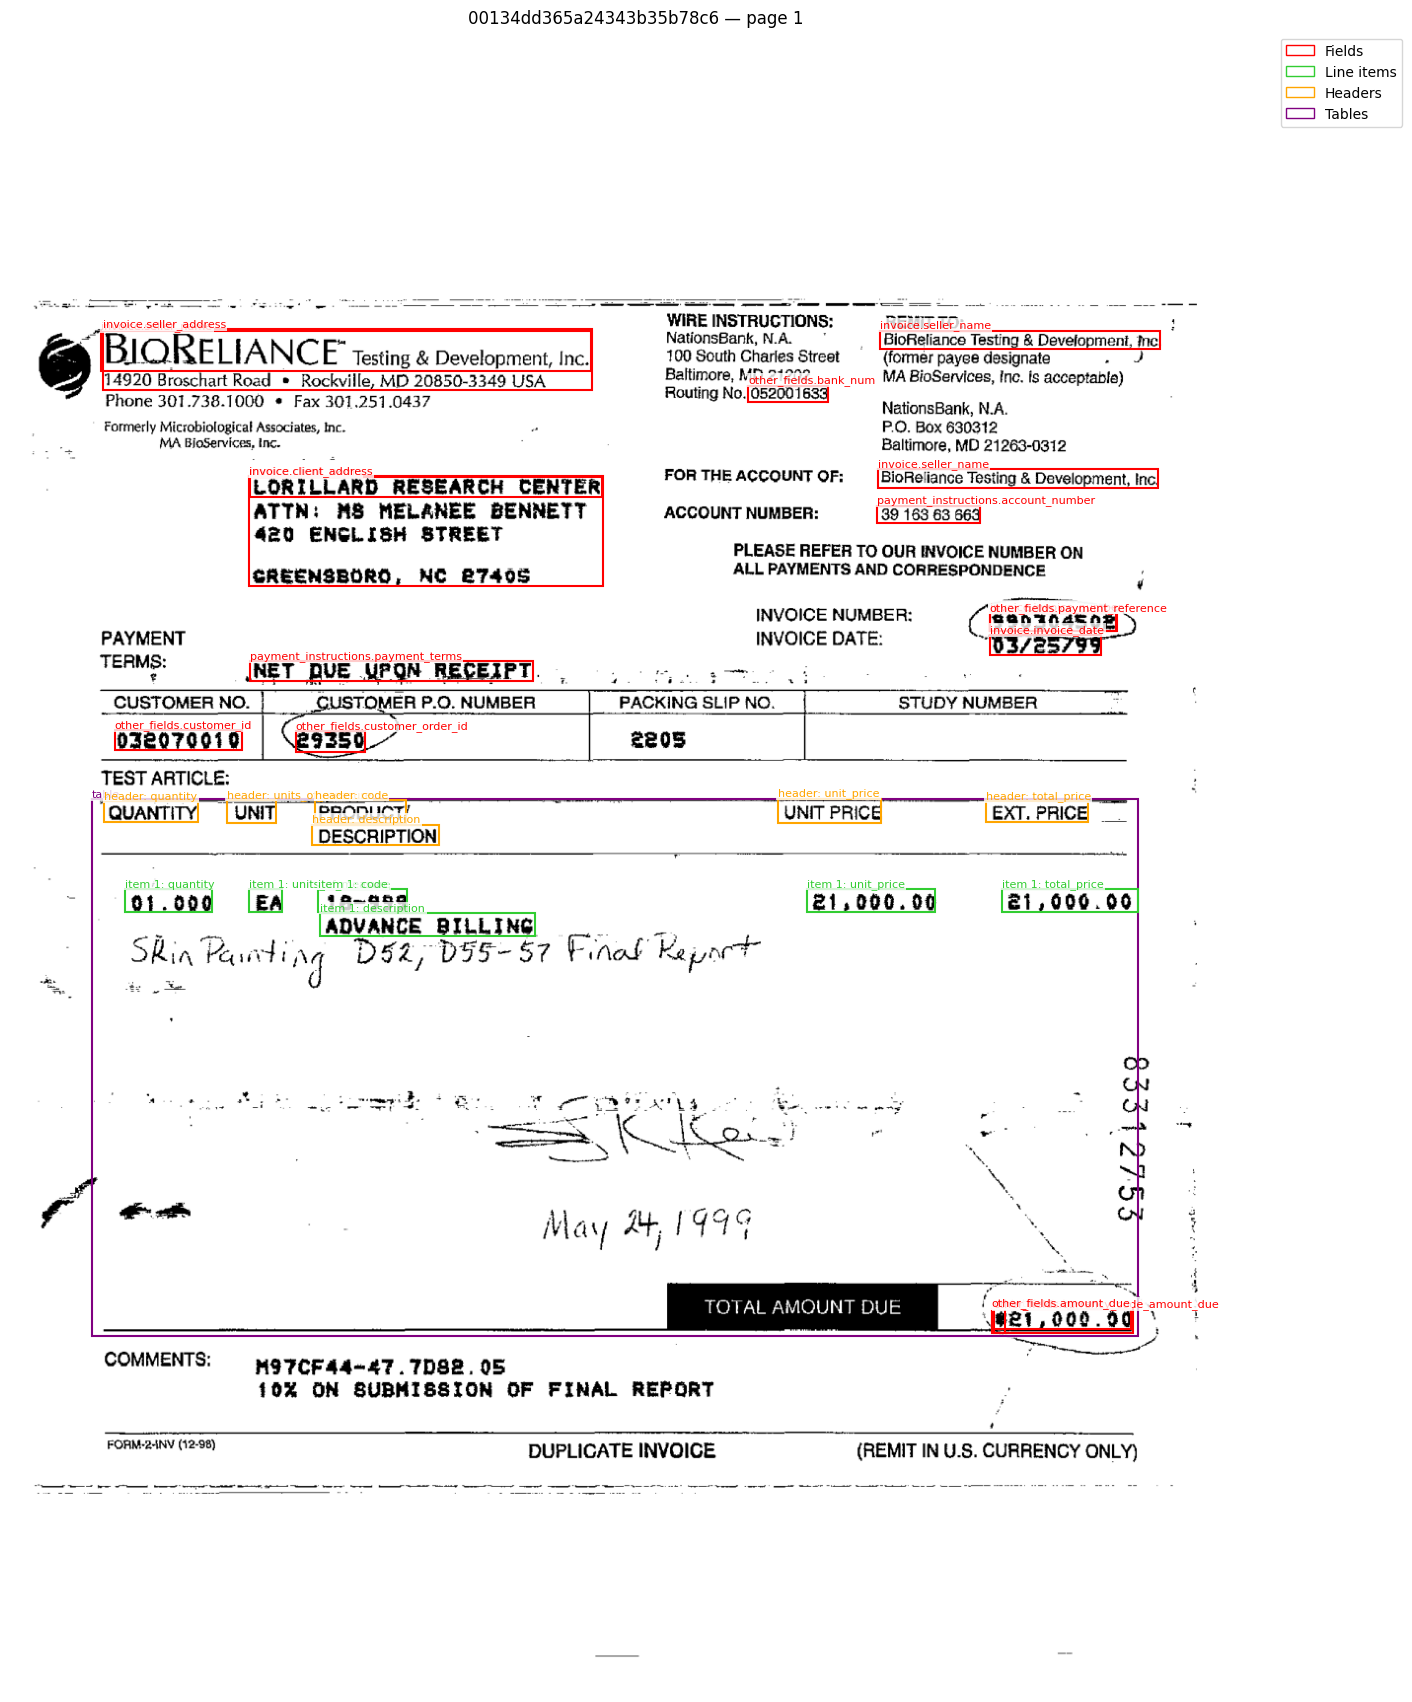

In [70]:
viewer.show(record)

In [71]:
record = loader.load("002f9b82b74f4258b3b072d0")

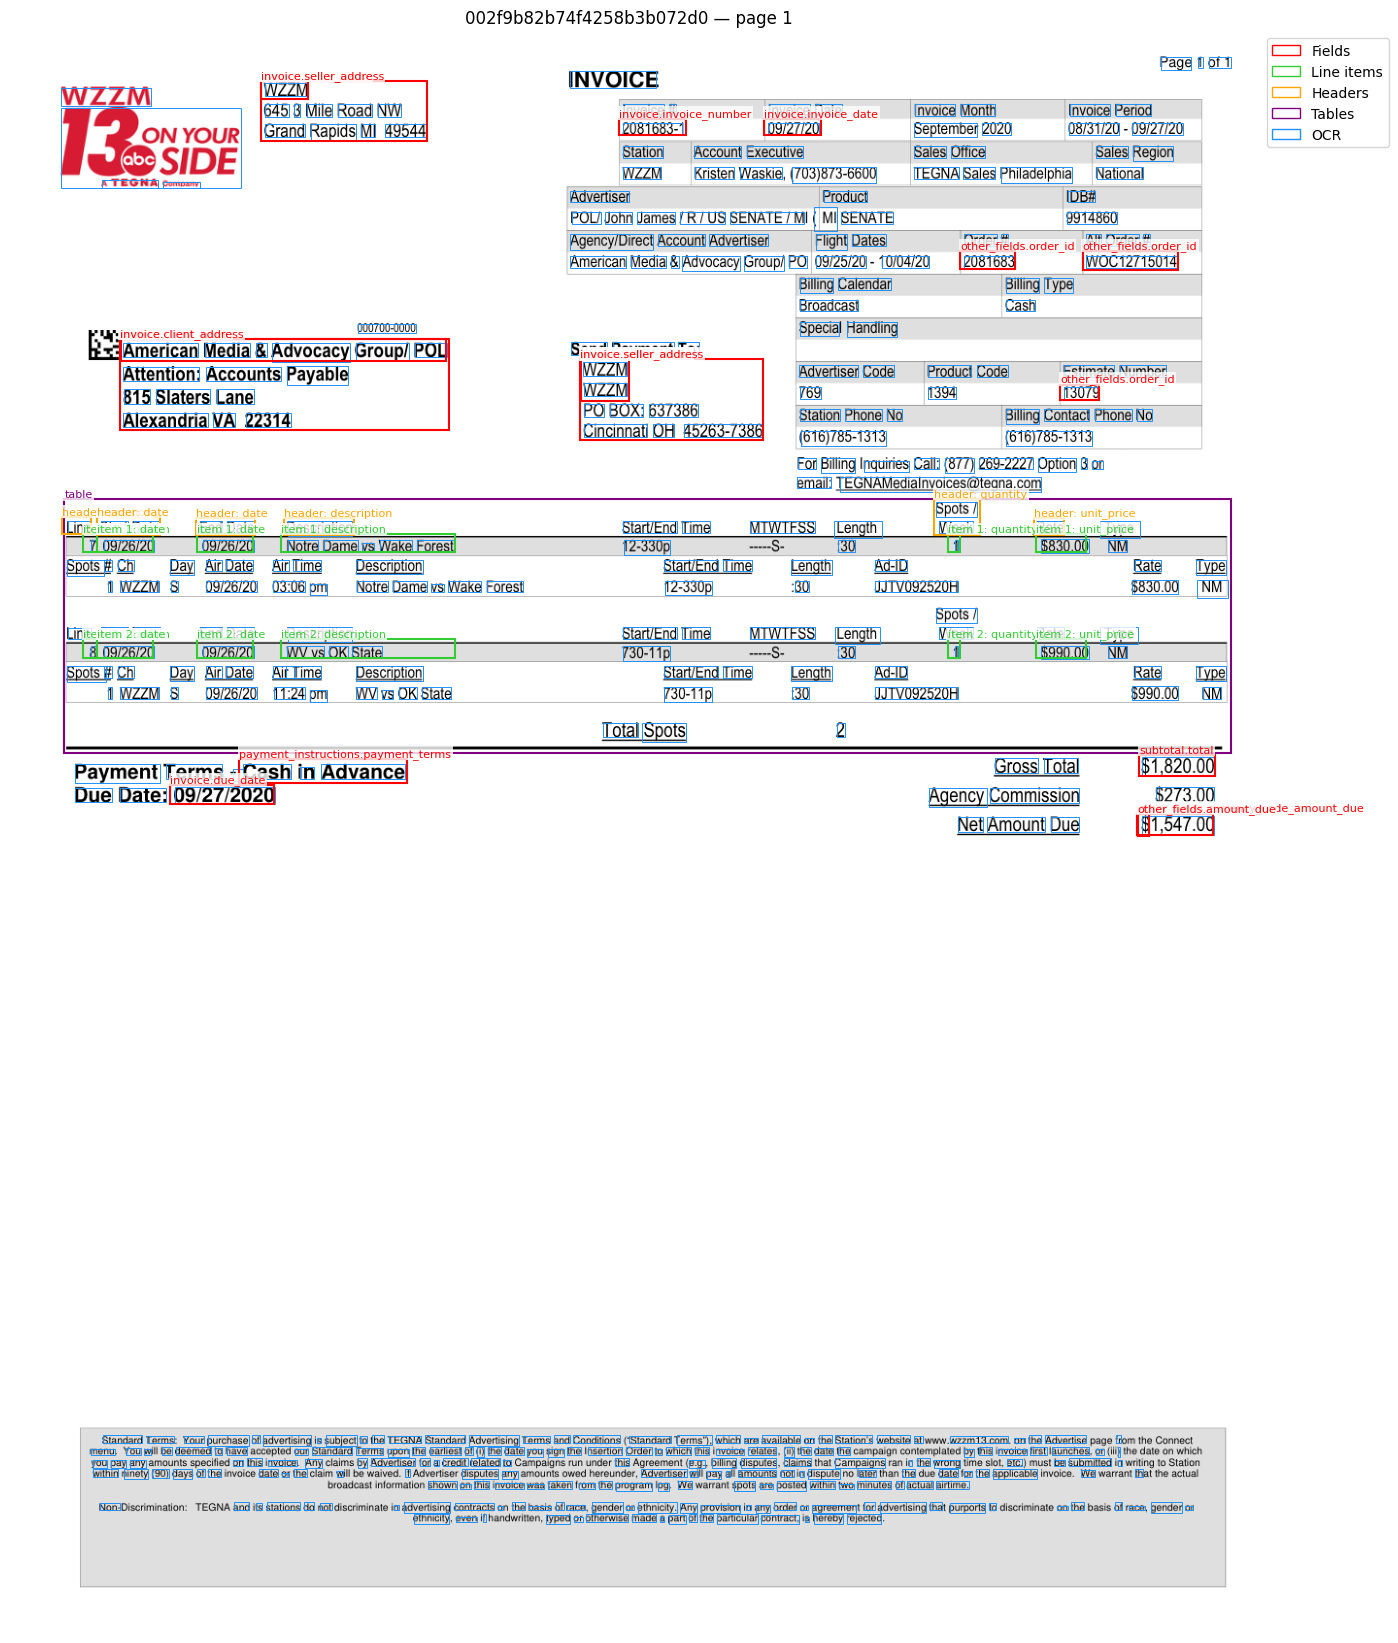

In [72]:
viewer.show(
    record,
    show_ocr=True,
    show_labels=True
)

In [84]:
loader = DocileDatasetLoader("/content/docile")

df = loader.to_dataframe("trainval")

Loading trainval: 100%|██████████| 5680/5680 [00:41<00:00, 137.15document/s]


In [81]:
df

,document_id,ocr_text,text_with_boxes,json_data,pdf_path
0,00134dd365a24343b35b78c6,"WIRE INSTRUCTIONS: NationsBank, N.A. Baltimore...","[{'text': 'WIRE', 'bbox': (0.5254137115839244,...",{'invoice': {'invoice_number': {'value': '9903...,/content/docile/pdfs/00134dd365a24343b35b78c6.pdf
1,00136a27c7774c1e8dc6b2f2,Please Remit To: KMOZ 92.3 The Moose 1360 E. S...,"[{'text': 'Please', 'bbox': (0.425882352941176...",{'invoice': {'invoice_number': {'value': '1768...,/content/docile/pdfs/00136a27c7774c1e8dc6b2f2.pdf
2,002e3cf97973428f905671b3,"UMI PUBLICATIONS, INC. P.O.BOX 30036 (28230) 1...","[{'text': 'UMI', 'bbox': (0.16857314870559903,...",{'invoice': {'invoice_number': {'value': '0960...,/content/docile/pdfs/002e3cf97973428f905671b3.pdf
3,002f9b82b74f4258b3b072d0,Page 1 of1 INVOICE Invoice # 2081683-1 Station...,"[{'text': 'Page', 'bbox': (0.9294117647058824,...",{'invoice': {'invoice_number': {'value': '2081...,/content/docile/pdfs/002f9b82b74f4258b3b072d0.pdf
4,003568b1286f4dab953fc2d5,Appud 10032089 WAIT KLEN SAINISIC Walt Klein &...,"[{'text': 'Appud', 'bbox': (0.6444444444444445...",{'invoice': {'invoice_number': {'value': '2329...,/content/docile/pdfs/003568b1286f4dab953fc2d5.pdf
...,...,...,...,...,...
5675,ffcaffe270654a87ad5a0631,Page 1of 2 INVOICE Property Invoice # Invoice ...,"[{'text': 'Page', 'bbox': (0.8590381426202321,...",{'invoice': {'invoice_number': {'value': '6657...,/content/docile/pdfs/ffcaffe270654a87ad5a0631.pdf
5676,ffcc5e0860f54314858dae44,"Invoice / Affidavit OHANA MEDIA GROUP, LLC. 83...","[{'text': 'Invoice', 'bbox': (0.39941176470588...",{'invoice': {'invoice_number': {'value': '6565...,/content/docile/pdfs/ffcc5e0860f54314858dae44.pdf
5677,ffcd395d52ff4a83bf659333,OCT 242001 U.S.A. Purchase Requisition P.0. Nu...,"[{'text': 'OCT', 'bbox': (0.6539365452408931, ...",{'invoice': {'invoice_number': {'value': '4251...,/content/docile/pdfs/ffcd395d52ff4a83bf659333.pdf
5678,ffd8e8fad20b4cc5984b3f26,"UNIVERSITY OF CALIFORNIA, DAVIS Accounting Off...","[{'text': 'UNIVERSITY', 'bbox': (0.33274231678...",{'invoice': {'invoice_number': {'value': '5927...,/content/docile/pdfs/ffd8e8fad20b4cc5984b3f26.pdf


In [85]:
record = loader.load("00134dd365a24343b35b78c6")

assert all(
    record.ocr_text[word.start:word.end] == word.text
    for word in record.text_with_boxes
)


In [86]:
def flatten_field_paths(
    data: dict,
    prefix: str = "",
) -> list[str]:
    """Return dotted paths for non-empty string values in a nested JSON object."""
    paths = []

    for key, value in data.items():
        path = f"{prefix}.{key}" if prefix else key

        if isinstance(value, dict):
            paths.extend(flatten_field_paths(value, path))
        elif isinstance(value, list):
            for item in value:
                if isinstance(item, dict):
                    paths.extend(flatten_field_paths(item, path))
        elif isinstance(value, str) and value.strip():
            paths.append(path)

    return paths

In [87]:
set(flatten_field_paths(record.json_data))

{'invoice.client_address.value',
 'invoice.client_name.value',
 'invoice.invoice_date.value',
 'invoice.invoice_number.value',
 'invoice.seller_address.value',
 'invoice.seller_name.value',
 'items.fields.code.value',
 'items.fields.description.value',
 'items.fields.quantity.value',
 'items.fields.total_price.value',
 'items.fields.unit_price.value',
 'items.fields.units_of_measure.value',
 'line_item_headers.code.value',
 'line_item_headers.description.value',
 'line_item_headers.quantity.value',
 'line_item_headers.total_price.value',
 'line_item_headers.unit_price.value',
 'line_item_headers.units_of_measure.value',
 'metadata.currency',
 'metadata.document_type',
 'metadata.language',
 'metadata.original_filename',
 'metadata.page_to_table_grid.0.columns.column_type',
 'metadata.page_to_table_grid.0.rows.row_type',
 'metadata.page_to_table_grid.0.table_border_type',
 'metadata.page_to_table_grid.0.table_structure',
 'metadata.source',
 'other_fields.amount_due.value',
 'other_fiel

In [88]:
from collections import Counter

field_document_counts = Counter()

for json_data in df["json_data"]:
    target = json.loads(json_data) if isinstance(json_data, str) else json_data

    # A set ensures a field is counted at most once per document.
    field_document_counts.update(set(flatten_field_paths(target)))

field_coverage = (
    pd.DataFrame(
        field_document_counts.items(),
        columns=["field", "documents_with_field"],
    )
    .sort_values("documents_with_field", ascending=False)
    .reset_index(drop=True)
)

field_coverage["coverage"] = (
    field_coverage["documents_with_field"] / len(df)
)

In [89]:
field_coverage['field'].to_list()

['metadata.document_type',
 'metadata.original_filename',
 'metadata.language',
 'metadata.source',
 'metadata.currency',
 'invoice.client_name.value',
 'subtotal.total.value',
 'other_fields.amount_due.value',
 'metadata.page_to_table_grid.0.rows.row_type',
 'metadata.page_to_table_grid.0.table_border_type',
 'metadata.page_to_table_grid.0.table_structure',
 'metadata.page_to_table_grid.0.columns.column_type',
 'invoice.invoice_date.value',
 'invoice.seller_name.value',
 'invoice.client_address.value',
 'invoice.invoice_number.value',
 'invoice.seller_address.value',
 'items.fields.description.value',
 'other_fields.currency_code_amount_due.value',
 'items.fields.total_price.value',
 'items.fields.quantity.value',
 'line_item_headers.description.value',
 'line_item_headers.quantity.value',
 'line_item_headers.total_price.value',
 'items.fields.unit_price.value',
 'items.fields.date.value',
 'line_item_headers.unit_price.value',
 'line_item_headers.date.value',
 'other_fields.order_id.

In [90]:
field_document_counts

Counter({'items.fields.description.value': 4084,
         'payment_instructions.account_number.value': 112,
         'payment_instructions.payment_terms.value': 2041,
         'other_fields.payment_reference.value': 185,
         'invoice.seller_address.value': 4577,
         'other_fields.bank_num.value': 93,
         'invoice.client_name.value': 5488,
         'metadata.document_type': 5680,
         'items.fields.units_of_measure.value': 348,
         'metadata.language': 5680,
         'metadata.original_filename': 5680,
         'invoice.seller_name.value': 4968,
         'items.fields.code.value': 1052,
         'line_item_headers.total_price.value': 2769,
         'invoice.invoice_date.value': 5013,
         'items.fields.quantity.value': 3187,
         'metadata.source': 5680,
         'invoice.invoice_number.value': 4711,
         'line_item_headers.description.value': 3007,
         'items.fields.unit_price.value': 2721,
         'items.fields.total_price.value': 3654,
      

In [93]:
field_coverage[
        ["field", "documents_with_field", "coverage"]
    ].sort_values("coverage", ascending=False).to_dict(orient="records")

[{'field': 'metadata.document_type',
  'documents_with_field': 5680,
  'coverage': 1.0},
 {'field': 'metadata.original_filename',
  'documents_with_field': 5680,
  'coverage': 1.0},
 {'field': 'metadata.language', 'documents_with_field': 5680, 'coverage': 1.0},
 {'field': 'metadata.source', 'documents_with_field': 5680, 'coverage': 1.0},
 {'field': 'metadata.currency', 'documents_with_field': 5680, 'coverage': 1.0},
 {'field': 'invoice.client_name.value',
  'documents_with_field': 5488,
  'coverage': 0.9661971830985916},
 {'field': 'subtotal.total.value',
  'documents_with_field': 5337,
  'coverage': 0.939612676056338},
 {'field': 'other_fields.amount_due.value',
  'documents_with_field': 5294,
  'coverage': 0.9320422535211268},
 {'field': 'metadata.page_to_table_grid.0.rows.row_type',
  'documents_with_field': 5277,
  'coverage': 0.9290492957746479},
 {'field': 'metadata.page_to_table_grid.0.table_border_type',
  'documents_with_field': 5277,
  'coverage': 0.9290492957746479},
 {'fiel

## Investigate overlapping annotations

In [94]:
from itertools import combinations

import pandas as pd


def collect_boxes(data):
    boxes = []

    def add(fields, prefix):
        for name, field in fields.items():
            for bbox, page in zip(
                field["bbox"], field["pages"], strict=True
            ):
                boxes.append({
                    "field": f"{prefix}.{name}",
                    "text": field["value"],
                    "bbox": bbox,
                    "page": page,
                })

    for section in (
        "invoice",
        "payment_instructions",
        "subtotal",
        "other_fields",
    ):
        add(data.get(section, {}), section)

    for item in data.get("items", []):
        add(item["fields"], f"items[{item['line_item_id']}]")

    return boxes


def area(box):
    left, top, right, bottom = box
    return max(0, right - left) * max(0, bottom - top)

In [95]:
overlaps = []

for _, row in df.iterrows():
    boxes = collect_boxes(row["json_data"])

    for a, b in combinations(boxes, 2):
        if a["page"] != b["page"] or a["field"] == b["field"]:
            continue

        intersection = [
            max(a["bbox"][0], b["bbox"][0]),
            max(a["bbox"][1], b["bbox"][1]),
            min(a["bbox"][2], b["bbox"][2]),
            min(a["bbox"][3], b["bbox"][3]),
        ]

        smaller_area = min(area(a["bbox"]), area(b["bbox"]))

        if smaller_area == 0:
            continue

        overlap = area(intersection) / smaller_area

        if overlap >= 0.8:
            overlaps.append({
                "document_id": row["document_id"],
                "page": a["page"],
                "field_a": a["field"],
                "field_b": b["field"],
                "text_a": a["text"],
                "text_b": b["text"],
                "overlap": overlap,
            })

overlaps_df = pd.DataFrame(
    overlaps,
    columns=[
        "document_id", "page",
        "field_a", "field_b",
        "text_a", "text_b", "overlap",
    ],
)

In [96]:
overlaps_df

,document_id,page,field_a,field_b,text_a,text_b,overlap
0,00134dd365a24343b35b78c6,0,invoice.invoice_number,other_fields.payment_reference,990304502,990304502,0.989189
1,00134dd365a24343b35b78c6,0,invoice.seller_name,invoice.seller_address,"BIO RELIANCE Testing & Development, Inc.","BIORELIANCE- Testing & Development, Inc.\n1492...",0.997029
2,00134dd365a24343b35b78c6,0,invoice.client_name,invoice.client_address,LORILLARD RESEARCH CENTER,LORILLARD RESEARCH CENTER\nATTN: MS MELANEE BE...,1.000000
3,00134dd365a24343b35b78c6,0,subtotal.total,other_fields.currency_code_amount_due,"$21,000.00",$,0.971429
4,00134dd365a24343b35b78c6,0,subtotal.total,other_fields.amount_due,"$21,000.00","$21,000.00",1.000000
...,...,...,...,...,...,...,...
21986,ffd8e8fad20b4cc5984b3f26,0,invoice.client_name,invoice.client_address,Dr. Bruce D. Davies\nPhilip Morris U.S.A.,Dr. Bruce D. Davies\nPhilip Morris U.S.A.\n420...,0.939672
21987,ffd8e8fad20b4cc5984b3f26,0,subtotal.total,other_fields.currency_code_amount_due,"$66,103.20",$,0.924407
21988,ffd8e8fad20b4cc5984b3f26,0,subtotal.total,other_fields.amount_due,"$66,103.20","$66,103.20",0.991471
21989,ffeeeefed0b24da28a16c8a4,1,subtotal.total,other_fields.amount_due,"1,925.00","$1,925.00",1.000000


In [101]:
overlaps_df.to_csv('/content/drive/MyDrive/ocr/overlaps.csv')

In [104]:
df.to_parquet("/content/drive/MyDrive/ocr/docile_df.parquet")

In [100]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [97]:
overlaps_df.groupby(["field_a", "field_b"]).size().reset_index(name="count").sort_values("count", ascending=False)

,field_a,field_b,count
3,invoice.client_name,invoice.client_address,4684
26,invoice.seller_name,invoice.seller_address,4624
492,subtotal.total,other_fields.amount_due,3448
452,other_fields.currency_code_amount_due,other_fields.amount_due,3161
495,subtotal.total,other_fields.currency_code_amount_due,2077
...,...,...,...
50,items[11].date,items[12].date,1
51,items[11].date,items[13].date,1
36,items[10].code,items[16].code,1
38,items[10].description,items[12].description,1
